# Engagement Atlas
## What public workforce surveys can—and cannot—tell an HR leader

**Margarita Bermejo Cano · HR analytics portfolio · Public organization aggregates**

A reproducible investigation of the US Office of Personnel Management's Federal
Employee Viewpoint Survey (FEVS), using published agency-level index results for
2017–2024. No employee records, simulated outcomes, private customer data, or
invented survey scores are used.

**Reading route:** evidence audit → distributions → trends → associations →
annual changes → next-year prediction → uncertainty → organizational profiles →
responsible HR decisions.

Scores are **0–100 published favorable-response index values**, not a validated
individual engagement scale. A one-point difference is one index point; it is
not a one-point change on a 0–10 employee rating scale.

Run the parent pipeline first; this notebook reads its persisted evidence and
does **not** retrain the headline forecasting or full-feature clustering models.
Lightweight sensitivity diagnostics are recomputed and checked below. See
`METHODOLOGY.md` for assumptions, equations, sources, and execution instructions.

## 0. Decision log: freeze the question before looking at results

| Decision | Rationale / boundary |
|---|---|
| Source | Fully public OPM agency aggregates; never respondent microdata |
| Scope | Rolling 2021 and 2024 EEI/GSI publications, yielding 2017–2024 |
| Unit | Organization-year for panel descriptions; organization for latest-year views |
| Sampling | Full processed panel; pair plots alone may use a seeded display sample |
| EDA depth | Quick + standard + in-depth, with tests limited to meaningful units |
| Missingness | Preserve unknown / unmatched values; no zero filling |
| Outliers | Flag plausible extremes for review; retain, never automatically trim |
| Comparison | Equal organization weighting, not a national employee estimate |
| Forecast | Predict next-year agency EEI using only prior-year published indexes |
| Selection | Expanding-window development CV; calibration then final temporal test |
| Interpretation | Associations and exploratory profiles, not intervention effects |
| Review gate | Source comparability, index overlap, nonresponse, and coverage |

**Open questions:** How much do agency entry/exit and name changes affect trends?
Does persistence beat additional predictors? Are intervals sufficiently reliable
under year-to-year shifts? What complementary qualitative evidence would change
an HR decision? Dynamic evidence below answers the empirical parts without
pre-writing favorable results.

In [1]:
import json
import platform
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "atlas" / "source.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start this notebook from engagement-atlas or its notebooks directory.")
sys.path.insert(0, str(ROOT))
from atlas.methods import benjamini_hochberg, paired_error_comparison
from atlas.source import CORE, DOWNLOADS, INTENTION_CROSSWALK, LICENSE_URL, SOURCE_URL
from atlas.statistics import balanced_longitudinal, intention_analysis

FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 42
sns.set_style("whitegrid")
sns.set_palette("colorblind")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 35)

def finish(fig, name):
    fig.savefig(FIGURES / f"notebook_{name}.png", dpi=100, bbox_inches="tight")
    plt.show()
    plt.close(fig)

required = {
    "agency_panel": ROOT / "data" / "processed" / "agency_panel.csv",
    "atlas": ROOT / "outputs" / "atlas.json",
    "forecast_panel": ROOT / "outputs" / "forecast_panel.csv",
    "annual_changes": ROOT / "outputs" / "annual_changes.csv",
}
missing_files = [str(p.relative_to(ROOT)) for p in required.values() if not p.is_file()]
if missing_files:
    raise FileNotFoundError("Run the parent pipeline first. Missing: " + ", ".join(missing_files))
df = pd.read_csv(required["agency_panel"])
evidence = json.loads(required["atlas"].read_text(encoding="utf-8"))
forecast_panel = pd.read_csv(required["forecast_panel"])
deltas = pd.read_csv(required["annual_changes"])
if df.empty or df.duplicated(["organization", "year"]).any():
    raise ValueError("Expected a nonempty, unique organization-year panel; investigate ingestion.")

def find_section(required_keys, node=evidence):
    # Identify persisted method outputs by their documented schema, not display names.
    if isinstance(node, dict):
        if set(required_keys).issubset(node):
            return node
        for child in node.values():
            found = find_section(required_keys, child)
            if found is not None:
                return found
    elif isinstance(node, list):
        for child in node:
            found = find_section(required_keys, child)
            if found is not None:
                return found
    return None

forecast_result = find_section(["selected", "cv", "interval", "metrics"])
changes_result = find_section(["coefficients", "correlations", "conditionNumber"])
clusters = find_section(["candidateScores", "profiles", "points", "variance"])
if any(item is None for item in [forecast_result, changes_result, clusters]):
    raise ValueError("atlas.json lacks the expected forecasting/change/clustering evidence.")
labels = {"engagement": "Employee Engagement Index", **CORE,
          "pay_satisfaction": "Pay satisfaction", "job_satisfaction": "Job satisfaction",
          "organization_satisfaction": "Organization satisfaction",
          "recommendation": "Recommendation"}
index_cols = [c for c in labels if c in df and df[c].notna().any()]
latest_year = int(df.year.max())
latest = df.loc[df.year.eq(latest_year)].copy()
print("Python version:", platform.python_version())
display(pd.DataFrame({"package": ["pandas", "numpy", "scipy", "scikit-learn",
                                 "seaborn", "nbformat", "nbclient"],
                      "version": [version(p) for p in ["pandas", "numpy", "scipy",
                                                      "scikit-learn", "seaborn",
                                                      "nbformat", "nbclient"]]}))

Python version: 3.11.9


,package,version
0,pandas,2.3.3
1,numpy,2.4.6
2,scipy,1.17.1
3,scikit-learn,1.9.1
4,seaborn,0.13.2
5,nbformat,5.11.1
6,nbclient,0.11.0


## 1. Provenance and responsible use

These rows are **public organization aggregates**, so displaying agency names
and aggregate values is permissible. Survey respondents remain unobserved.
Published federal-government works are generally public domain under
[17 USC §105](https://www.law.cornell.edu/uscode/text/17/105); that does not
license every third-party asset, OPM mark, or linked work.

The newer rolling edition takes precedence for overlapping agency-year values.
Longitudinal names are whitespace-normalized and matched exactly—no fuzzy
identity guesses. The separate intention-report join uses the manually reviewed
abbreviation mapping documented in `DATA_SOURCES.md`, not an official OPM
harmonization table.
Blank-size governmentwide/tier summaries and overlapping overall parent rows
are excluded upstream. Defense components may remain; they are not necessarily
statistically independent institutions.

In [2]:
display(pd.DataFrame([{"publication": name, "url": url}
                      for name, url in DOWNLOADS.items()]))
print("Source landing page:", SOURCE_URL)
print("Public-domain legal reference:", LICENSE_URL)
print("Persisted JSON sections:", list(evidence))
manifest = find_section(["sha256", "url", "file"])
if manifest is not None:
    display(pd.DataFrame([manifest]))
print("All persisted source metadata and findings remain inspectable in the final appendix.")

,publication,url
0,2021-ee.xlsx,https://www.opm.gov/fevs/reports/data-reports/...
1,2024-ee.xlsx,https://www.opm.gov/fevs/reports/data-reports/...
2,2021-gs.xlsx,https://www.opm.gov/fevs/reports/data-reports/...
3,2024-gs.xlsx,https://www.opm.gov/fevs/reports/data-reports/...
4,2024-responses.xlsx,https://www.opm.gov/fevs/reports/data-reports/...
5,2024-intentions.xlsx,https://www.opm.gov/fevs/reports/data-reports/...


Source landing page: https://www.opm.gov/fevs/reports/data-reports/
Public-domain legal reference: https://www.law.cornell.edu/uscode/text/17/105
Persisted JSON sections: ['meta', 'annual', 'rows', 'correlations', 'models', 'clusters', 'changeAnalysis', 'intentionAnalysis', 'cohortSensitivity', 'quality', 'findings']
All persisted source metadata and findings remain inspectable in the final appendix.


## 2. Evidence audit: what is actually in the panel?

Repeated agency observations are **not independent respondents**. Distinguish
organization-year rows, unique agencies, and available survey respondents.
Response counts refer to the published 2024 response-rate report, not necessarily
the denominator of each weighted index or unweighted intention item.

In [3]:
overview = pd.Series({
    "organization_year_rows": len(df),
    "organizations": df.organization.nunique(),
    "columns": len(df.columns),
    "first_year": int(df.year.min()),
    "last_year": latest_year,
    "memory_MB": df.memory_usage(deep=True).sum() / 1024**2,
    "identical_duplicate_rows": int(df.duplicated().sum()),
    "duplicate_organization_years": int(df.duplicated(["organization", "year"]).sum()),
}, name="value")
display(overview.to_frame())
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nonmissing": df.notna().sum(),
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
    "unique": df.nunique(),
})
schema["cardinality_ratio"] = schema["unique"] / len(df)
display(schema)
display(df.head())
display(df.tail())
display(df.select_dtypes("number").describe().T)
for col in df.select_dtypes(include=["object", "category"]):
    print(col, "distinct categories:", df[col].nunique())
    display(df[col].value_counts(dropna=False).head(10).to_frame("organization-year rows"))
print("Dtype review: year is an integer time key; organization is an identifier, not a predictor.")

,value
organization_year_rows,630.000000
organizations,85.000000
columns,20.000000
first_year,2017.000000
last_year,2024.000000
memory_MB,0.194395
identical_duplicate_rows,0.000000
duplicate_organization_years,0.000000


,dtype,nonmissing,missing_n,missing_pct,unique,cardinality_ratio
organization,object,630,0,0.000000,85,0.134921
agency_size,object,630,0,0.000000,5,0.007937
year,int64,630,0,0.000000,8,0.012698
engagement,float64,630,0,0.000000,628,0.996825
intrinsic,float64,630,0,0.000000,628,0.996825
leaders,float64,630,0,0.000000,626,0.993651
supervisors,float64,630,0,0.000000,620,0.984127
satisfaction,float64,630,0,0.000000,627,0.995238
pay_satisfaction,float64,390,240,38.095238,390,0.619048
job_satisfaction,float64,390,240,38.095238,387,0.614286


,organization,agency_size,year,engagement,intrinsic,leaders,supervisors,satisfaction,pay_satisfaction,job_satisfaction,organization_satisfaction,recommendation,response_count,response_rate,surveyed,intent_leave,intent_retire,intent_external,intent_response_count,intent_source_code
0,AbilityOne Commission,Very Small,2017,65.153461,67.930925,59.129890,68.399568,60.182479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,American Battle Monuments Commission,Very Small,2017,59.308601,73.272206,38.884715,65.768882,56.143826,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Commission on Civil Rights,Very Small,2017,55.031122,62.101865,27.166319,75.825182,51.816265,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Commodity Futures Trading Commission,Small,2017,67.069803,68.024540,53.872989,79.311880,56.854511,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Consumer Product Safety Commission,Small,2017,73.078226,74.978633,64.093709,80.162335,70.324939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,organization,agency_size,year,engagement,intrinsic,leaders,supervisors,satisfaction,pay_satisfaction,job_satisfaction,organization_satisfaction,recommendation,response_count,response_rate,surveyed,intent_leave,intent_retire,intent_external,intent_response_count,intent_source_code
625,U.S. Office of Special Counsel,Small,2024,85.724666,88.576949,76.543945,92.053105,79.038172,69.105547,83.100806,81.314560,82.631773,70.0,58.3,120.0,NaN,NaN,NaN,NaN,NaN
626,U.S. Trade and Development Agency,Very Small,2024,85.219644,79.407886,86.390694,89.860351,67.279257,49.358934,64.174989,72.022256,83.560850,52.0,92.9,56.0,NaN,NaN,NaN,NaN,NaN
627,United States Department of the Air Force,Very Large,2024,73.440435,75.733411,63.942818,80.645076,64.564415,57.881879,68.942784,63.480093,67.952905,28490.0,18.4,154677.0,44.7,8.0,4.3,28490.0,Air Force
628,United States Department of the Army,Very Large,2024,75.208411,77.430814,66.159658,82.034761,68.380605,63.284491,72.086419,67.090689,71.060819,61640.0,30.6,201757.0,NaN,NaN,NaN,NaN,NaN
629,United States Department of the Navy,Very Large,2024,74.206142,76.446367,63.652217,82.519843,65.430248,57.866871,69.758793,63.826499,70.268830,47116.0,24.6,191251.0,NaN,NaN,NaN,NaN,NaN


,count,mean,std,min,25%,50%,75%,max
year,630.0,2020.542857,2.292014,2017.000000,2019.000000,2021.000000,2023.000000,2024.0
engagement,630.0,73.900482,8.695805,34.971528,68.708069,73.356588,78.733402,100.0
intrinsic,630.0,76.532048,7.356489,43.466425,72.347344,76.103021,80.329304,100.0
leaders,630.0,63.258133,13.016418,12.707564,55.648844,62.479009,70.595374,100.0
supervisors,630.0,81.914440,7.798639,38.520542,77.376955,82.753429,86.659140,100.0
satisfaction,630.0,68.921870,10.673737,24.831400,63.116803,68.501308,75.125720,100.0
pay_satisfaction,390.0,65.194112,9.967748,30.396182,59.448392,65.406288,71.280832,100.0
job_satisfaction,390.0,73.056371,9.885012,15.655055,67.942586,72.918755,78.276341,100.0
organization_satisfaction,390.0,68.524362,12.452454,8.039789,61.271885,68.125959,76.365368,100.0
recommendation,390.0,71.848720,12.557838,17.252073,65.393950,71.663946,79.621814,100.0


organization distinct categories: 85


... (2 outputs left out)

,organization-year rows
agency_size,
Small,224
Very Small,134
Medium,128
Very Large,72
Large,72


intent_source_code distinct categories: 34


,organization-year rows
intent_source_code,
NaN,596
CSOSA,1
USDA,1
DOC,1
ED,1
DOE,1
HHS,1
DHS,1
HUD,1


Dtype review: year is an integer time key; organization is an identifier, not a predictor.


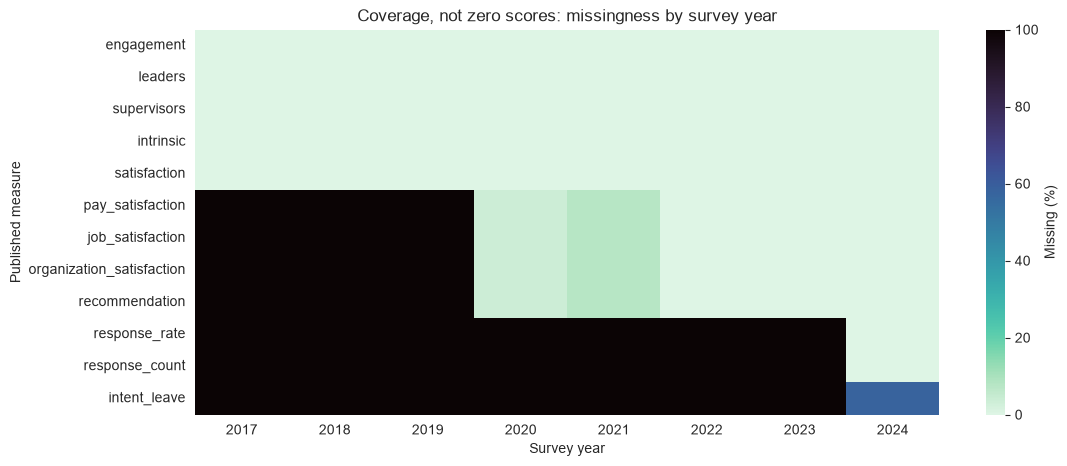

,measure,n,IQR_flags_retained,outside_0_100
0,engagement,630,27,0
1,leaders,630,23,0
2,supervisors,630,10,0
3,intrinsic,630,28,0
4,satisfaction,630,23,0
5,pay_satisfaction,390,10,0
6,job_satisfaction,390,15,0
7,organization_satisfaction,390,8,0
8,recommendation,390,10,0
9,response_rate,81,1,0


IQR flags are descriptive review signals, not deletion rules. 2024-only auxiliary measures are structurally missing in earlier years.
Response-count availability: 81 of 81 latest-year organizations.


In [4]:
missing_by_year = df.groupby("year")[index_cols + [
    c for c in ["response_rate", "response_count", "intent_leave"] if c in df
]].agg(lambda s: s.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(missing_by_year.T, cmap="mako_r", vmin=0, vmax=100,
            cbar_kws={"label": "Missing (%)"}, ax=ax)
ax.set(title="Coverage, not zero scores: missingness by survey year",
       xlabel="Survey year", ylabel="Published measure")
finish(fig, "missingness")

quality = []
for col in index_cols + [c for c in ["response_rate", "intent_leave",
                                   "intent_retire", "intent_external"] if c in df]:
    values = df[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    quality.append({"measure": col, "n": len(values),
                    "IQR_flags_retained": int(((values < lo) | (values > hi)).sum()),
                    "outside_0_100": int(((values < 0) | (values > 100)).sum())})
display(pd.DataFrame(quality))
print("IQR flags are descriptive review signals, not deletion rules. "
      "2024-only auxiliary measures are structurally missing in earlier years.")
print("Response-count availability:",
      latest["response_count"].notna().sum() if "response_count" in latest else 0,
      "of", len(latest), "latest-year organizations.")

## 3. Distribution atlas: variation is the first HR question

Use the latest year to avoid treating repeated agencies as independent.
Histograms show distribution shape; box/violin plots reveal spread and overlap.
IQR extremes may reflect genuine organizational experiences. Normality tests
below are shape diagnostics—not an automatic switch between methods.

Available pay, job, organization-satisfaction, and recommendation measures are
included in latest-year distributions and correlations even when insufficient
historical coverage excludes them from forecasting. Descriptive availability
is not a license to impute an invented historical series.

,measure,latest_year_n,role
0,engagement,81,Forecast input and EDA
1,leaders,81,Forecast input and EDA
2,supervisors,81,Forecast input and EDA
3,intrinsic,81,Forecast input and EDA
4,satisfaction,81,Forecast input and EDA
5,pay_satisfaction,81,Supplemental latest-year EDA; not a forecast i...
6,job_satisfaction,81,Supplemental latest-year EDA; not a forecast i...
7,organization_satisfaction,81,Supplemental latest-year EDA; not a forecast i...
8,recommendation,81,Supplemental latest-year EDA; not a forecast i...


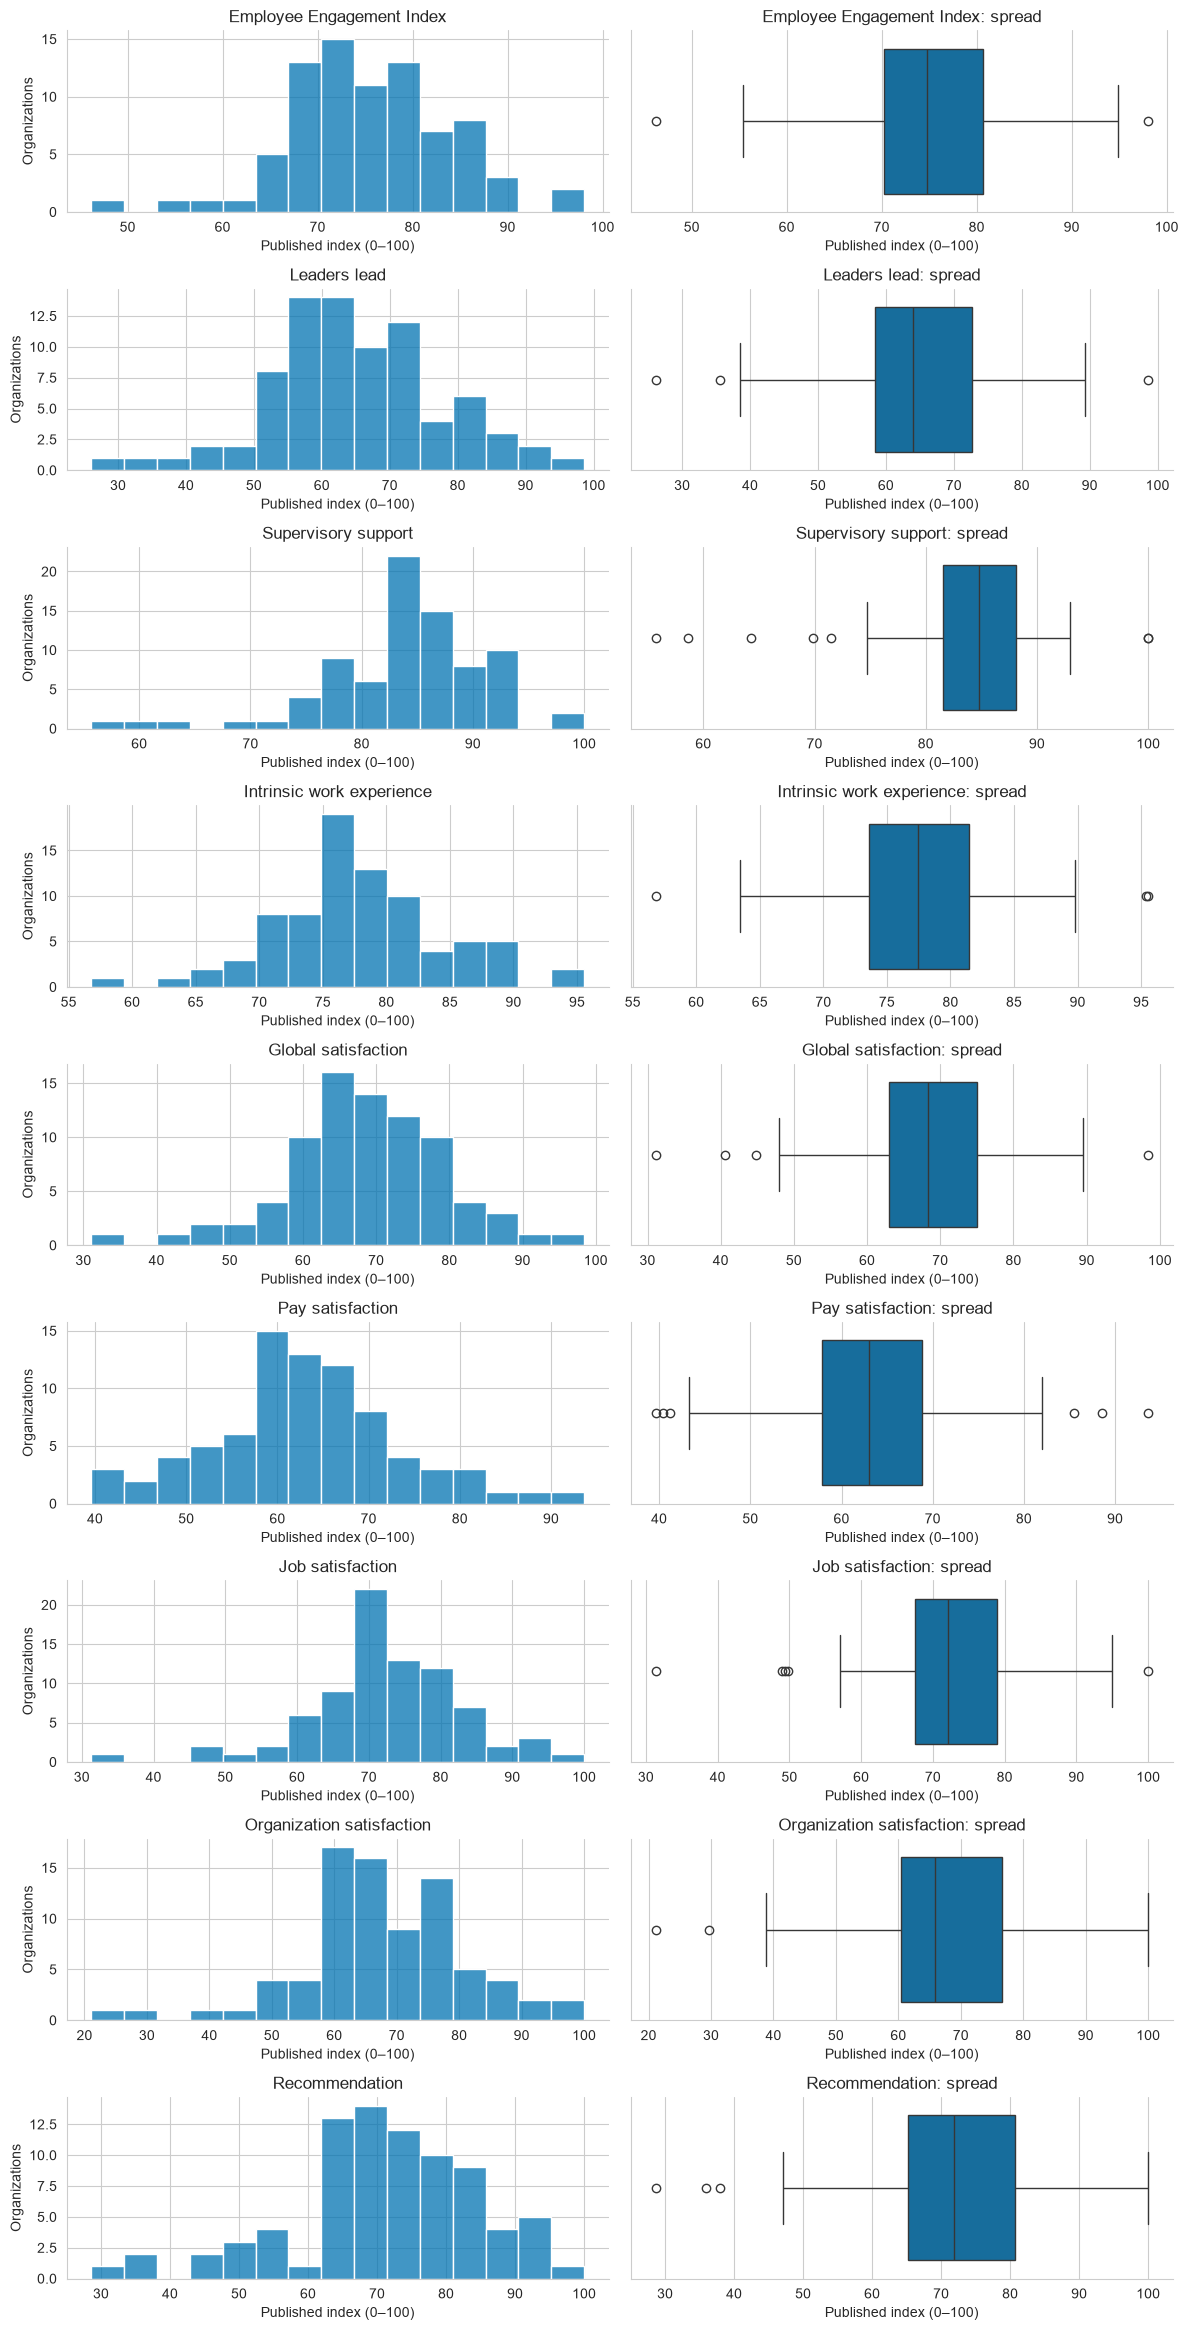

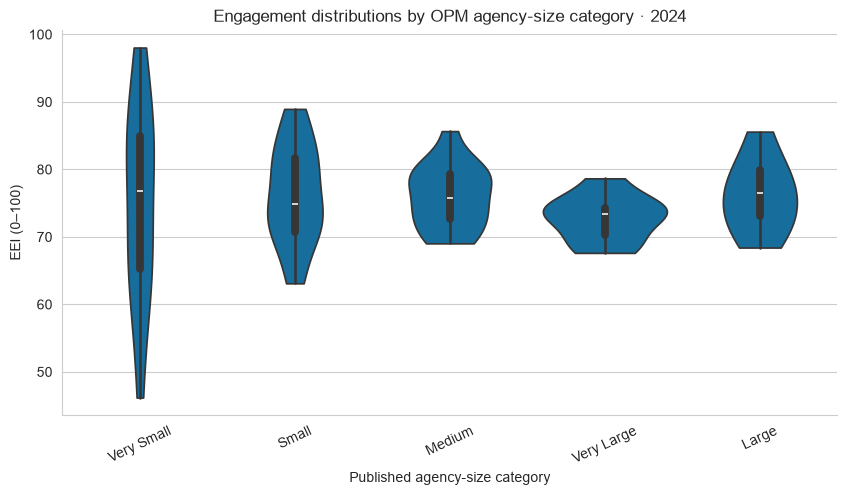

,count,median,mean,std
agency_size,,,,
Large,9,76.512831,76.081068,5.384679
Medium,16,75.706125,75.989879,4.662910
Small,29,74.844826,76.299081,7.218181
Very Large,9,73.440435,72.823896,3.430941
Very Small,18,76.774662,75.132008,14.139867


,measure,n_organizations,skewness,excess_kurtosis,shapiro_W,diagnostic_p
0,engagement,81,-0.278603,1.505247,0.978200,0.182444
1,leaders,81,-0.133856,0.674658,0.987396,0.616092
2,supervisors,81,-1.208487,3.281080,0.915537,0.000053
3,intrinsic,81,0.044618,0.821545,0.985866,0.517594
4,satisfaction,81,-0.386059,1.583034,0.974477,0.105335
5,pay_satisfaction,81,0.206159,0.551256,0.984638,0.444862
6,job_satisfaction,81,-0.553764,2.334236,0.962767,0.018774
7,organization_satisfaction,81,-0.472471,1.581113,0.970297,0.056559
8,recommendation,81,-0.669012,0.755895,0.967279,0.036210


Do not interpret a nonsignificant Shapiro result as proof of normality.


In [5]:
cols = [c for c in index_cols if latest[c].notna().sum() >= 3]
predictive_keys = {item["feature"] for item in forecast_result["importance"]}
display(pd.DataFrame([
    {"measure": col, "latest_year_n": int(latest[col].notna().sum()),
     "role": "Forecast input and EDA" if col in predictive_keys else
             "Supplemental latest-year EDA; not a forecast input"}
    for col in cols
]))
fig, axes = plt.subplots(len(cols), 2, figsize=(12, 2.6 * len(cols)), squeeze=False)
for row, col in enumerate(cols):
    sns.histplot(latest, x=col, bins=15, ax=axes[row, 0])
    axes[row, 0].set(title=labels[col], xlabel="Published index (0–100)",
                     ylabel="Organizations")
    sns.boxplot(latest, x=col, ax=axes[row, 1])
    axes[row, 1].set(title=f"{labels[col]}: spread", xlabel="Published index (0–100)")
fig.tight_layout()
finish(fig, "distributions")

fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(latest, x="agency_size", y="engagement", inner="box", cut=0, ax=ax)
ax.set(title=f"Engagement distributions by OPM agency-size category · {latest_year}",
       xlabel="Published agency-size category", ylabel="EEI (0–100)")
ax.tick_params(axis="x", rotation=25)
finish(fig, "size_violin")
display(latest.groupby("agency_size").engagement.agg(["count", "median", "mean", "std"]))

shape_rows = []
for col in cols:
    values = latest[col].dropna()
    if values.nunique() < 2:
        continue
    probe = values.sample(min(len(values), 5000), random_state=SEED)
    statistic, p = stats.shapiro(probe)
    shape_rows.append({"measure": col, "n_organizations": len(values),
                       "skewness": values.skew(), "excess_kurtosis": values.kurt(),
                       "shapiro_W": statistic, "diagnostic_p": p})
display(pd.DataFrame(shape_rows))
print("Do not interpret a nonsignificant Shapiro result as proof of normality.")

## 4. Relationships: covariance is not leverage

Pearson describes **linear** association; Spearman describes **monotonic rank**
association and is useful with bounded, rounded published values. Both are
ecological agency-level summaries. Leaders, supervisors, and intrinsic work
experience are EEI components; satisfaction items may also share content.
High correlations therefore partly reflect the measurement architecture, not
independently discovered management drivers.

The latest-year tests below form one explicitly defined BH-adjusted exploratory
family: each available index versus engagement. They do not prove causality,
nor account fully for related agencies or selective response.

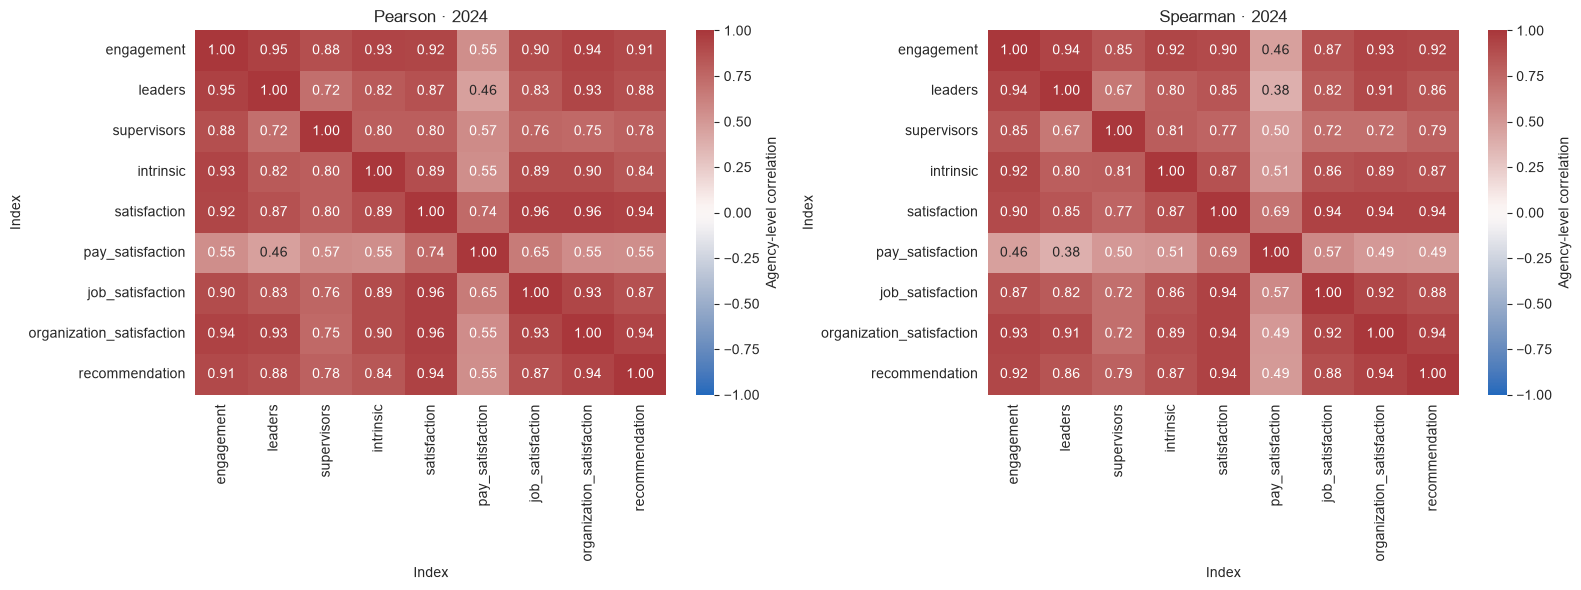

,index_1,index_2,Spearman_rho
0,engagement,leaders,0.936360
1,engagement,supervisors,0.847690
2,engagement,intrinsic,0.923080
3,engagement,satisfaction,0.901491
4,engagement,job_satisfaction,0.873374
5,engagement,organization_satisfaction,0.931843
6,engagement,recommendation,0.917547
7,leaders,intrinsic,0.798013
8,leaders,satisfaction,0.845190
9,leaders,job_satisfaction,0.818157


,feature,rho,p_exploratory,n_organizations,q_BH
0,leaders,0.936360,1.156044e-37,81,9.248353e-37
6,organization_satisfaction,0.931843,1.589260e-36,81,6.357040e-36
2,intrinsic,0.923080,1.592019e-34,81,4.245385e-34
7,recommendation,0.917547,2.221573e-33,81,4.443146e-33
3,satisfaction,0.901491,1.828799e-30,81,2.926079e-30
5,job_satisfaction,0.873374,2.124336e-26,81,2.832448e-26
1,supervisors,0.847690,1.866658e-23,81,2.133323e-23
4,pay_satisfaction,0.459756,1.575634e-05,81,1.575634e-05


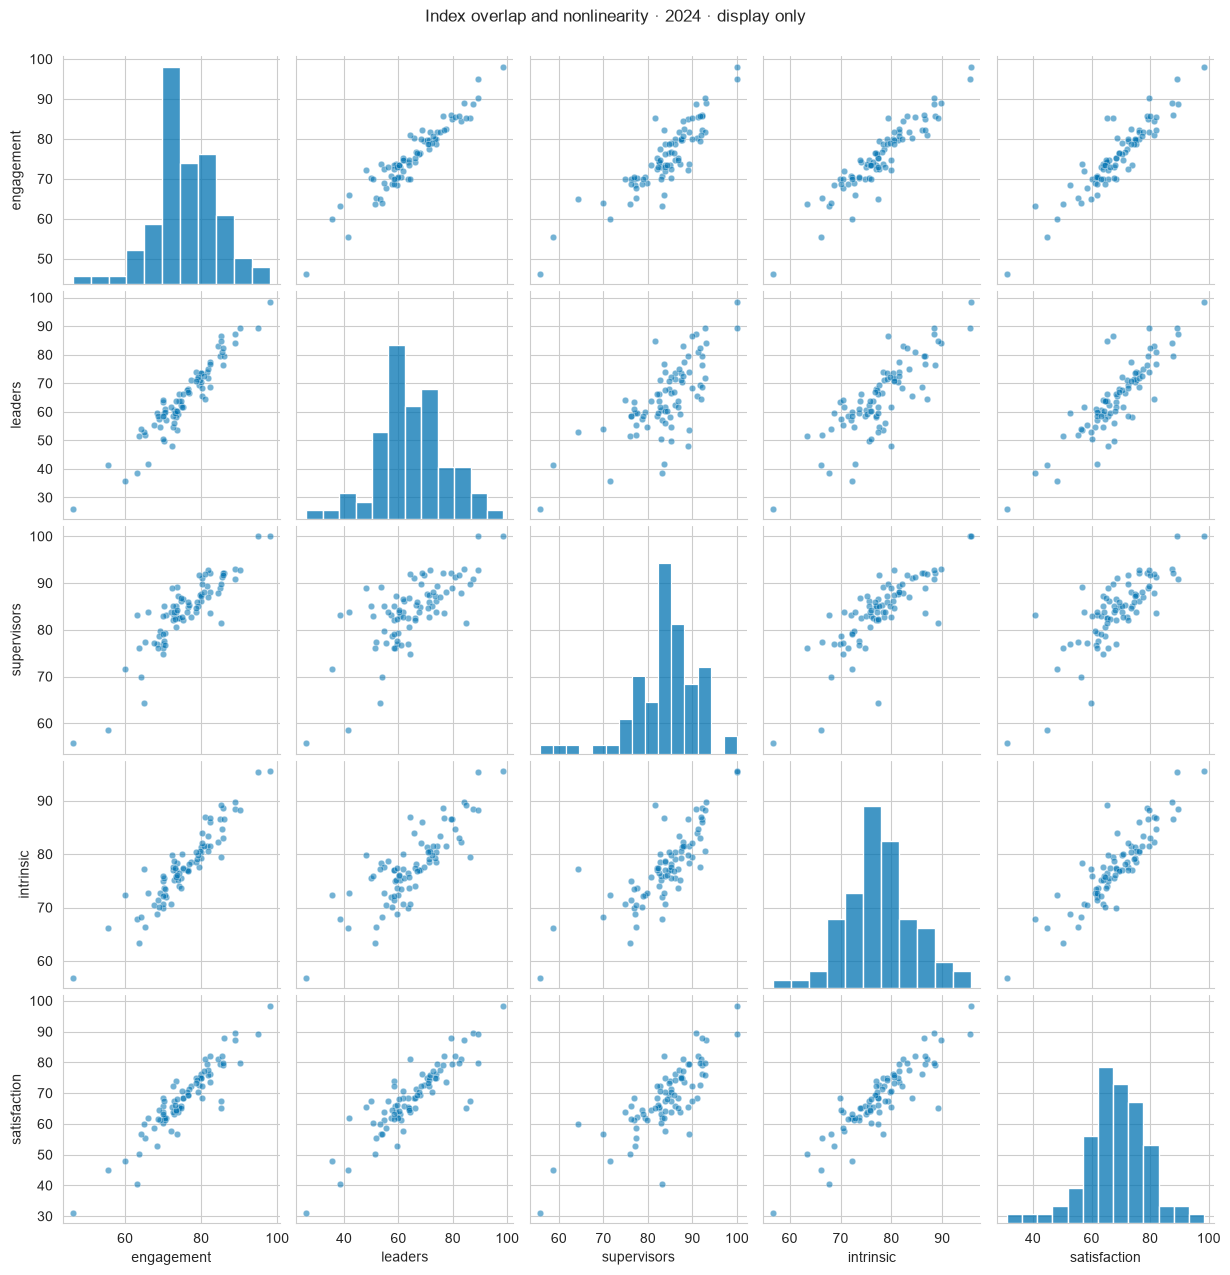

In [6]:
corr_cols = [c for c in index_cols if latest[c].notna().mean() > 0.4
             and latest[c].nunique() > 1]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = latest[corr_cols].corr(method=method, min_periods=5)
    sns.heatmap(corr, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
                cmap="vlag", ax=ax, cbar_kws={"label": "Agency-level correlation"})
    ax.set(title=f"{method.title()} · {latest_year}", xlabel="Index", ylabel="Index")
fig.tight_layout()
finish(fig, "correlations")
high = []
corr = latest[corr_cols].corr(method="spearman", min_periods=5)
for i, first in enumerate(corr_cols):
    for second in corr_cols[i + 1:]:
        value = corr.loc[first, second]
        if abs(value) > 0.7:
            high.append({"index_1": first, "index_2": second, "Spearman_rho": value})
display(pd.DataFrame(high))

association_rows = []
for col in corr_cols:
    if col == "engagement":
        continue
    pair = latest[[col, "engagement"]].dropna()
    if len(pair) >= 5 and pair.nunique().min() > 1:
        rho, p = stats.spearmanr(pair[col], pair.engagement)
        association_rows.append({"feature": col, "rho": rho, "p_exploratory": p,
                                 "n_organizations": len(pair)})
associations = pd.DataFrame(association_rows)
if not associations.empty:
    associations["q_BH"] = benjamini_hochberg(associations.p_exploratory)
    display(associations.sort_values("q_BH"))
pair_cols = corr_cols[:5]
if len(pair_cols) >= 2:
    sample = latest[pair_cols].sample(min(1000, len(latest)), random_state=SEED)
    grid = sns.pairplot(sample, diag_kind="hist", plot_kws={"alpha": 0.55, "s": 22})
    grid.fig.suptitle(f"Index overlap and nonlinearity · {latest_year} · display only", y=1.02)
    finish(grid.fig, "pairplot")

## 5. Time: compare composition before telling a national story

Each annual mean/median weights observed agencies equally. The 95% median
intervals resample agencies within that year; they are **not survey-design
confidence intervals for the federal workforce**.

The balanced cohort below requires an exact-name agency with nonmissing EEI in
**every observed year**, matching the pipeline's persisted `balancedTrend`
and `balancedOrgCount`. It is not merely the final forecast-test roster.
Balancing does not solve survivorship or name-change bias.
Context around 2020 may affect comparability: consult OPM's year-specific
technical reports before asserting specific redesign, mode, or fieldwork facts.

,year,n_organizations,mean,median,median_low,median_high
0,2017,76,70.666875,69.365313,68.543651,71.462035
1,2018,77,70.206765,68.626594,67.573398,70.849720
2,2019,78,70.458330,69.677369,68.161657,70.890603
3,2020,81,76.272317,75.412678,73.297573,76.929604
4,2021,78,76.825399,76.820485,75.248445,78.042658
5,2022,77,75.475969,75.929710,74.306054,76.681310
6,2023,82,75.388170,74.471695,73.332818,77.345653
7,2024,81,75.568299,74.772565,73.370837,78.671859


Balanced exact-name agencies: 72 of 85


n               72.000000
firstYear     2017.000000
lastYear      2024.000000
meanChange       5.551059
low              3.731584
high             7.243143
dtype: float64

Sensitivity comparison: the same reporting names in every observed year. Paired agency-bootstrap intervals describe this observed cohort, not national employee sampling uncertainty. Related agencies weaken the resampling assumption. Names do not guarantee unchanged agency boundaries or workforces.


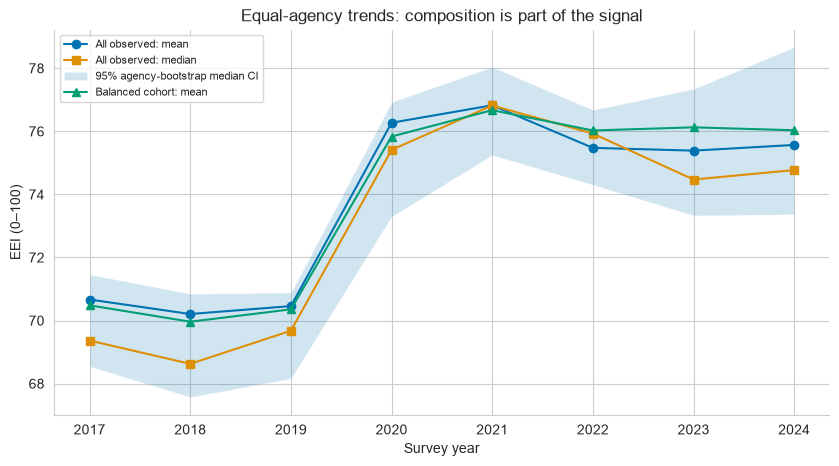

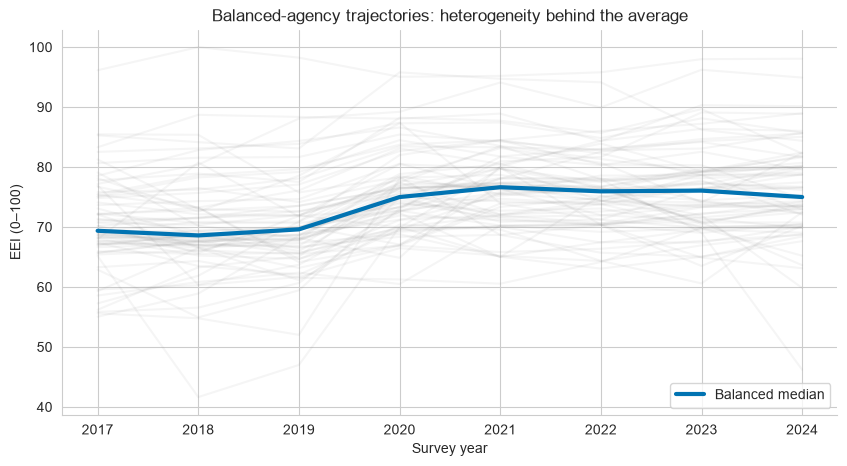

In [7]:
rng = np.random.default_rng(SEED)
annual_rows = []
for year, group in df.groupby("year"):
    values = group.engagement.dropna().to_numpy()
    boot = np.median(values[rng.integers(0, len(values), (2000, len(values)))], axis=1)
    low, high = np.quantile(boot, [0.025, 0.975])
    annual_rows.append({"year": int(year), "n_organizations": len(values),
                        "mean": values.mean(), "median": np.median(values),
                        "median_low": low, "median_high": high})
annual = pd.DataFrame(annual_rows)
wide = df.pivot(index="organization", columns="year", values="engagement")
balanced = wide.dropna()
if len(balanced) != forecast_result["balancedOrgCount"]:
    raise ValueError("Balanced-cohort count differs between CSV and JSON; regenerate the pipeline.")
persisted_balanced = pd.DataFrame(forecast_result["balancedTrend"]).set_index("year")
if len(balanced) and not np.allclose(
    balanced.mean().to_numpy(),
    persisted_balanced.loc[balanced.columns, "engagement"].to_numpy()
):
    raise ValueError("Balanced-cohort means differ between CSV and JSON; regenerate the pipeline.")
display(annual)
print("Balanced exact-name agencies:", len(balanced), "of", df.organization.nunique())
cohort_check = balanced_longitudinal(df)
if not np.allclose(
    [cohort_check[k] for k in ["meanChange", "low", "high"]],
    [evidence["cohortSensitivity"][k] for k in ["meanChange", "low", "high"]]
):
    raise ValueError("Balanced endpoint diagnostics disagree with persisted evidence.")
display(pd.Series({k: cohort_check[k] for k in
                   ["n", "firstYear", "lastYear", "meanChange", "low", "high"]}))
print(cohort_check["interpretation"])
fig, ax = plt.subplots()
ax.plot(annual.year, annual["mean"], marker="o", label="All observed: mean")
ax.plot(annual.year, annual["median"], marker="s", label="All observed: median")
ax.fill_between(annual.year.to_numpy(), annual.median_low.to_numpy(),
                annual.median_high.to_numpy(), alpha=0.18, label="95% agency-bootstrap median CI")
if len(balanced):
    ax.plot(balanced.columns, balanced.mean(), marker="^", label="Balanced cohort: mean")
ax.set(title="Equal-agency trends: composition is part of the signal",
       xlabel="Survey year", ylabel="EEI (0–100)")
ax.legend(fontsize=8)
finish(fig, "annual_trends")
if len(balanced):
    fig, ax = plt.subplots()
    for organization in balanced.index:
        ax.plot(balanced.columns, balanced.loc[organization], color="gray", alpha=0.08)
    ax.plot(balanced.columns, balanced.median(), color=sns.color_palette()[0],
            linewidth=3, label="Balanced median")
    ax.set(title="Balanced-agency trajectories: heterogeneity behind the average",
           xlabel="Survey year", ylabel="EEI (0–100)")
    ax.legend()
    finish(fig, "balanced_trajectories")

## 6. Annual changes: a more demanding association question

Only consecutive-year, exact-name observations are differenced. The persisted
regression adjusts for common year effects and simultaneous standardized
feature changes; organization-clustered standard errors allow within-agency
dependence. Coefficients mean **EEI points per one SD of annual feature change**,
not points per one-unit level difference. BH correction applies to this
coefficient family.

Whole-agency trajectory bootstrap intervals accompany Spearman change
correlations. The displayed `pNaive` ignores repeated agencies and is not the
primary inferential evidence. Differencing does not remove changing response
composition, reverse causality, index overlap, or time-varying confounding.

,value
n,540.000000
organizations,84.000000
r2,0.999932
conditionNumber,13.222355


,feature,label,rho,pNaive,low,high,n
0,leaders,Leaders lead,0.893367,4.616042e-189,0.863912,0.915247,540
1,intrinsic,Intrinsic work experience,0.828256,1.945596e-137,0.777578,0.872727,540
2,satisfaction,Global satisfaction,0.779831,1.574330e-111,0.731928,0.823734,540
3,supervisors,Supervisory support,0.742158,1.485464e-95,0.681305,0.796301,540


,feature,label,estimate,low,high,p,q
0,leaders,Leaders lead,2.713735,2.694499,2.732971,2.358959e-125,9.435837e-125
1,supervisors,Supervisory support,1.842292,1.829023,1.855561,8.880456e-125,1.776091e-124
2,intrinsic,Intrinsic work experience,1.649752,1.632768,1.666735,6.355184e-112,8.473579e-112
3,satisfaction,Global satisfaction,0.007557,-0.010021,0.025135,3.949774e-01,3.949774e-01


,organization,year,engagement,leaders,supervisors,intrinsic,satisfaction
0,AbilityOne Commission,2018,-23.521611,-22.346202,-29.879026,-18.339605,-25.736734
1,AbilityOne Commission,2019,5.361261,8.909672,5.641408,1.532704,11.247615
2,AbilityOne Commission,2020,22.997487,18.840176,27.032749,23.119534,26.482654
3,AbilityOne Commission,2021,-4.990598,-9.533536,-4.194699,-2.243558,1.823986
4,AbilityOne Commission,2022,2.458301,12.059905,8.327650,-12.012653,-14.620083


,count,mean,std,min,25%,50%,75%,max
year,540.0,2021.018519,2.011015,2018.000000,2019.000000,2021.000000,2023.000000,2024.000000
engagement,540.0,0.940342,5.407000,-23.521611,-1.376074,0.579293,2.723101,46.119700
leaders,540.0,1.059199,8.171635,-34.205596,-2.528366,0.846828,4.171795,50.887756
supervisors,540.0,1.021436,5.529596,-29.879026,-0.940711,0.645563,2.539608,52.964541
intrinsic,540.0,0.747798,4.936621,-18.339605,-1.429862,0.575451,2.446751,36.278034
satisfaction,540.0,0.462562,7.008535,-29.243643,-2.677878,0.406838,3.020516,56.316867


Rows in persisted annual-change panel: 540 | Unique organizations: 84


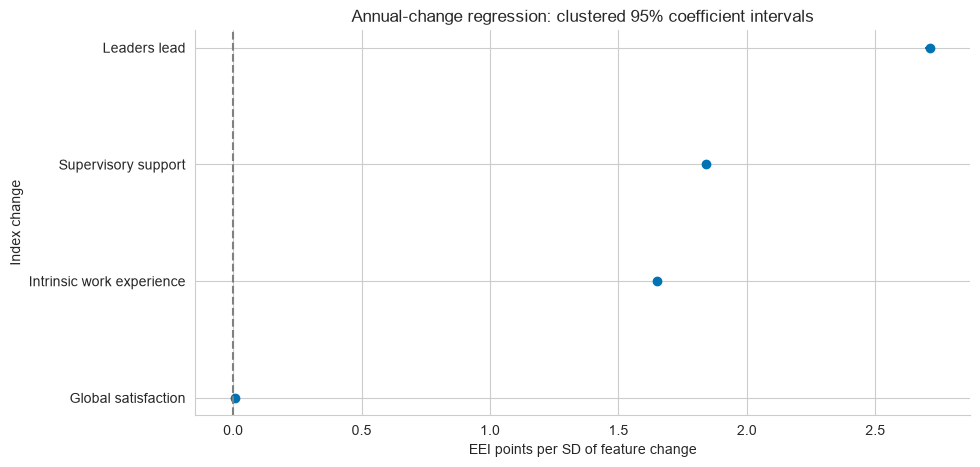

**Collinearity gate:** Review the condition number and interval widths. Shared index components can make adjusted signs unstable; a surprising coefficient is not an intervention recommendation.

In [8]:
display(pd.Series({key: changes_result[key] for key in
                   ["n", "organizations", "r2", "conditionNumber"]}).to_frame("value"))
change_corr = pd.DataFrame(changes_result["correlations"])
coefficients = pd.DataFrame(changes_result["coefficients"])
display(change_corr)
display(coefficients)
display(deltas.head())
display(deltas.select_dtypes("number").describe().T)
print("Rows in persisted annual-change panel:", len(deltas),
      "| Unique organizations:", deltas.organization.nunique())
if not coefficients.empty:
    ordered = coefficients.sort_values("estimate")
    fig, ax = plt.subplots(figsize=(10, 5))
    positions = np.arange(len(ordered))
    ax.hlines(positions, ordered.low, ordered.high, color=sns.color_palette()[0])
    ax.scatter(ordered.estimate, positions)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(positions, ordered.label)
    ax.set(title="Annual-change regression: clustered 95% coefficient intervals",
           xlabel="EEI points per SD of feature change", ylabel="Index change")
    finish(fig, "change_coefficients")
display(Markdown("**Collinearity gate:** Review the condition number and interval widths. "
                 "Shared index components can make adjusted signs unstable; "
                 "a surprising coefficient is not an intervention recommendation."))

## 7. Forecasting lab: does complexity beat last year's score?

**Target:** next-year published agency EEI. Exact-name joins require consecutive
years. Prior-year EEI and source-selected index features are used; 2024-only
response and intention measures are excluded from forecasting.

**Development:** target years 2018–2022. The first two supply warm-up training;
expanding-window scored folds therefore begin later than 2018. Mean fold MAE
(equal weighting of folds, not agencies pooled across years) selects persistence
or one of five fixed configurations: Ridge, ElasticNet, Random Forest,
Extra Trees, and histogram gradient boosting. Imputation/scaling fit within
each training partition. Predictions are clipped to the index's 0–100 domain.

Models are frozen after training on targets before 2023. **2023 calibrates**
uncertainty; **2024 is the final temporal test**, never a model-selection set.
The retrospective table includes all candidates for transparency, not to
replace the development winner with the best test score.

,partition,organization_year_rows,organizations,target_years
0,Development,382,78,"[2018, 2019, 2020, 2021, 2022]"
1,Calibration,77,77,[2023]
2,Final test,81,81,[2024]


name,Elastic net,Extra trees,Gradient boosting,Persistence,Random forest,Ridge
year,,,,,,
2020,6.356366,6.178597,6.295945,6.278404,6.363127,6.353845
2021,3.554938,3.577244,4.500012,3.551717,3.938198,3.556733
2022,2.197092,2.242987,3.008826,2.019579,2.575237,2.242476


,name,mean_development_fold_MAE
0,Persistence,3.949900
1,Extra trees,3.999609
2,Elastic net,4.036132
3,Ridge,4.051018
4,Random forest,4.292187
5,Gradient boosting,4.601595


,name,mae,rmse,r2,MAE_CI_low,MAE_CI_high,selected_by_development
0,Extra trees,3.265599,5.383990,0.580865,2.384636,4.306573,False
1,Ridge,3.290118,6.337052,0.419342,2.255372,4.644123,False
2,Elastic net,3.296099,6.314850,0.423403,2.258197,4.648655,False
3,Persistence,3.339533,6.990795,0.293359,2.172126,4.908818,True
4,Gradient boosting,3.425500,5.506110,0.561635,2.541143,4.456046,False
5,Random forest,3.494346,5.537327,0.556650,2.587074,4.508638,False


Locked winner: Persistence
Final test year: 2024


,name,n,difference,low,high,fractionBetter,medianAbsoluteError
0,Extra trees,81,0.073933,-0.521608,0.920523,0.469136,1.667370
1,Ridge,81,0.049415,-0.319544,0.449390,0.481481,1.594828
2,Elastic net,81,0.043434,-0.343785,0.465334,0.518519,1.715835
3,Gradient boosting,81,-0.085968,-0.757852,0.792072,0.456790,1.672406
4,Random forest,81,-0.154814,-0.769788,0.679707,0.358025,2.028712


Positive differences mean lower MAE than persistence on the same held-out agencies. Percentile 95% intervals use 5,000 paired agency resamples with seed 42. These post-hoc diagnostics do not change validation-based model selection, adjust for five comparisons, or include model-training uncertainty. Related agencies may weaken the independent-agency resampling assumption.


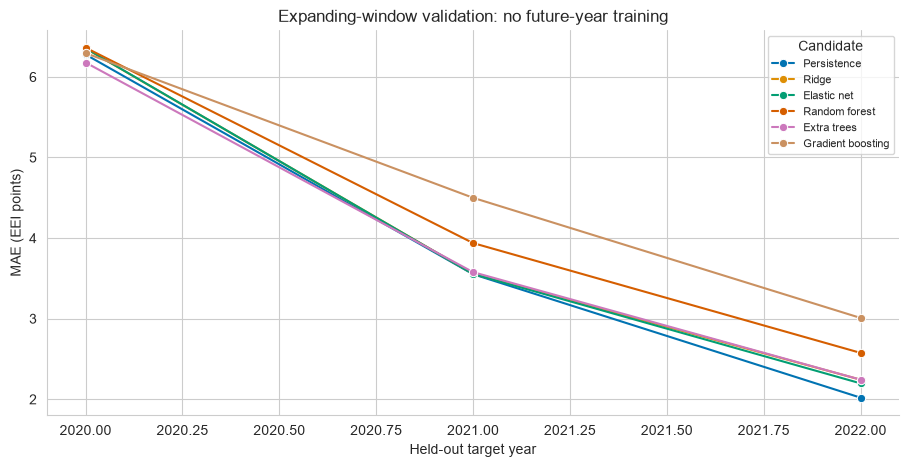

In [9]:
split_rows = []
for name, subset in [
    ("Development", forecast_panel[forecast_panel.target_year <
                                    forecast_result["calibrationYear"]]),
    ("Calibration", forecast_panel[forecast_panel.target_year ==
                                    forecast_result["calibrationYear"]]),
    ("Final test", forecast_panel[forecast_panel.target_year == forecast_result["testYear"]]),
]:
    split_rows.append({"partition": name, "organization_year_rows": len(subset),
                       "organizations": subset.organization.nunique(),
                       "target_years": sorted(subset.target_year.unique().tolist())})
display(pd.DataFrame(split_rows))
cv = pd.DataFrame(forecast_result["cv"])
display(cv.pivot(index="year", columns="name", values="mae"))
selection = pd.DataFrame(forecast_result["selection"])
display(selection.rename(columns={"mae": "mean_development_fold_MAE"}))
metrics = pd.DataFrame(forecast_result["metrics"])
metrics["selected_by_development"] = metrics.name.eq(forecast_result["selected"])
display(metrics.rename(columns={"low": "MAE_CI_low", "high": "MAE_CI_high"}))
print("Locked winner:", forecast_result["selected"])
print("Final test year:", forecast_result["testYear"])
comparison_predictions = pd.DataFrame(forecast_result["modelPredictions"])
comparisons = pd.DataFrame(forecast_result["pairedComparisons"])
for row in comparisons.itertuples():
    candidate = comparison_predictions[comparison_predictions.model == row.name]
    check = paired_error_comparison(candidate.actual, candidate.predicted, candidate.baseline)
    if not np.allclose([check[k] for k in ["difference", "low", "high"]],
                       [row.difference, row.low, row.high]):
        raise ValueError(f"Paired forecast comparison mismatch: {row.name}")
display(comparisons)
print(forecast_result["comparisonNotes"])
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(cv, x="year", y="mae", hue="name", marker="o", ax=ax)
ax.set(title="Expanding-window validation: no future-year training",
       xlabel="Held-out target year", ylabel="MAE (EEI points)")
ax.legend(title="Candidate", fontsize=8)
finish(fig, "temporal_cv")

## 8. Calibration and error: uncertainty is part of the product

A split-conformal-style radius uses the finite-sample order statistic of 2023
absolute residuals, with 90% nominal coverage. The clipped intervals are
evaluated in 2024. Temporal shifts and related agencies undermine exchangeability:
**nominal coverage is an aspiration, not a guaranteed future-year promise**.

MAE confidence intervals resample final-test organizations (one row per agency).
They quantify uncertainty conditional on the observed organizations and year,
not model-selection uncertainty or all future workforce environments.

,interval evidence
nominal,0.9
coverage,0.864198
covered,70
n,81
coverageLow,0.772969
coverageHigh,0.922445
coverageNote,The illustrative 95% Wilson interval assumes i...
width,12.483332
radius,6.283458


,organization,actual,predicted,baseline,lower,upper,residual,absolute_error,covered,interval_width
63,Privacy and Civil Liberties Oversight Board,81.091228,34.971528,34.971528,28.688070,41.254986,46.119700,46.119700,False,12.566916
38,Inter-American Foundation,46.190933,69.060956,69.060956,62.777498,75.344414,-22.870023,22.870023,False,12.566916
1,Advisory Council on Historic Preservation,66.051740,84.125991,84.125991,77.842533,90.409449,-18.074251,18.074251,False,12.566916
4,Commission on Civil Rights,59.827320,71.918750,71.918750,65.635292,78.202208,-12.091430,12.091430,False,12.566916
3,American Battle Monuments Commission,72.458096,60.591090,60.591090,54.307632,66.874548,11.867006,11.867006,False,12.566916
2,African Development Foundation,85.170497,74.516591,74.516591,68.233133,80.800049,10.653906,10.653906,False,12.566916
37,Institute of Museum and Library Services,82.335445,74.109705,74.109705,67.826247,80.393163,8.225740,8.225740,False,12.566916
62,Postal Regulatory Commission,82.246889,89.654280,89.654280,83.370822,95.937738,-7.407391,7.407391,False,12.566916
32,Federal Maritime Commission,63.627229,70.778145,70.778145,64.494687,77.061603,-7.150916,7.150916,False,12.566916
69,U.S. Access Board,64.881849,71.762723,71.762723,65.479265,78.046181,-6.880874,6.880874,False,12.566916


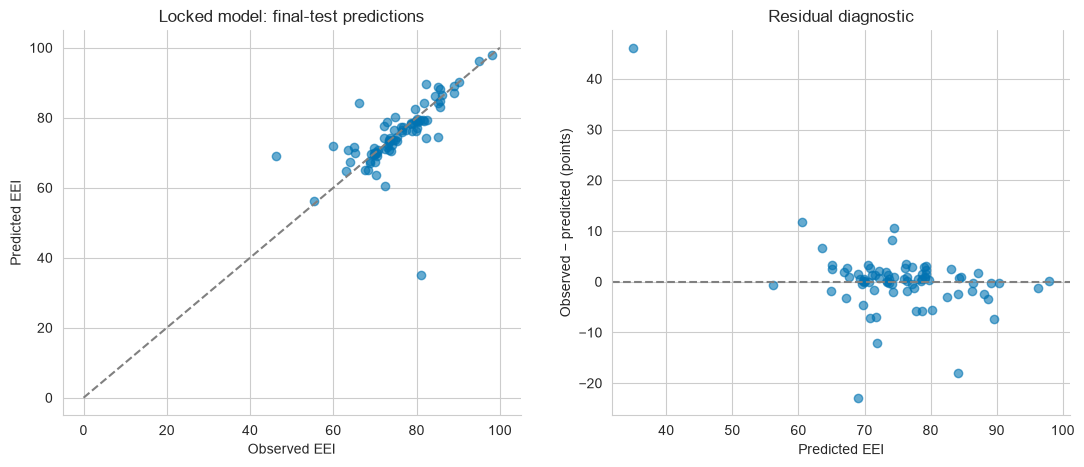

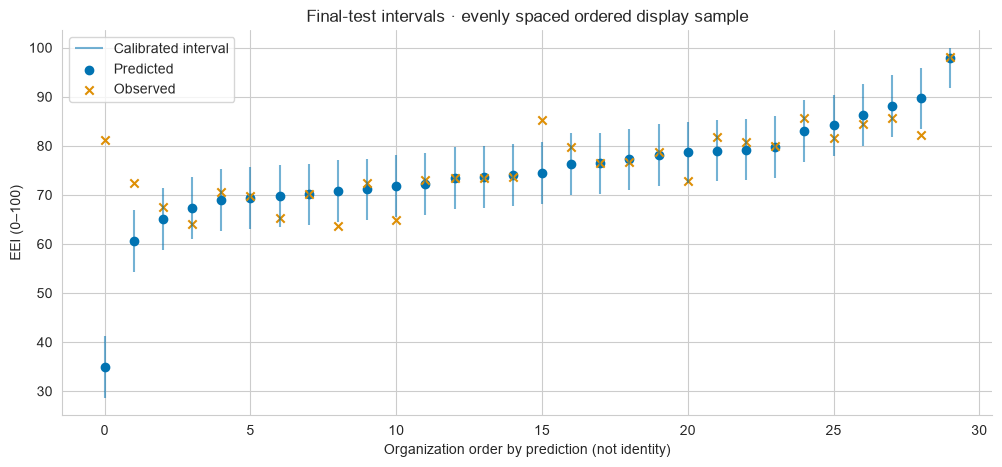

,n_organizations,MAE,observed_coverage,mean_width
agency_size,,,,
Large,9,1.053705,1.000000,12.566916
Medium,16,1.669640,1.000000,12.566916
Small,29,2.238686,0.931034,12.566916
Very Large,9,1.254990,1.000000,12.566916
Very Small,18,8.782653,0.500000,12.190787


Size-category diagnostics are organizational error checks, not employee fairness tests.


In [10]:
predictions = pd.DataFrame(forecast_result["predictions"])
predictions["residual"] = predictions.actual - predictions.predicted
predictions["absolute_error"] = predictions.residual.abs()
predictions["covered"] = predictions.actual.between(predictions.lower, predictions.upper)
predictions["interval_width"] = predictions.upper - predictions.lower
display(pd.Series(forecast_result["interval"]).to_frame("interval evidence"))
display(predictions.sort_values("absolute_error", ascending=False).head(10))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(predictions.actual, predictions.predicted, alpha=0.6)
axes[0].plot([0, 100], [0, 100], "--", color="gray")
axes[0].set(title="Locked model: final-test predictions", xlabel="Observed EEI",
            ylabel="Predicted EEI")
axes[1].scatter(predictions.predicted, predictions.residual, alpha=0.6)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(title="Residual diagnostic", xlabel="Predicted EEI",
            ylabel="Observed − predicted (points)")
finish(fig, "forecast_diagnostics")
sample = predictions.sort_values("predicted").iloc[
    np.linspace(0, len(predictions) - 1, min(30, len(predictions)), dtype=int)
]
fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(len(sample))
ax.vlines(positions, sample.lower, sample.upper, alpha=0.55, label="Calibrated interval")
ax.scatter(positions, sample.predicted, label="Predicted")
ax.scatter(positions, sample.actual, marker="x", label="Observed")
ax.set(title="Final-test intervals · evenly spaced ordered display sample",
       xlabel="Organization order by prediction (not identity)", ylabel="EEI (0–100)")
ax.legend()
finish(fig, "forecast_intervals")
error_audit = predictions.merge(latest[["organization", "agency_size"]], on="organization",
                                how="left", validate="one_to_one")
display(error_audit.groupby("agency_size").agg(
    n_organizations=("organization", "size"), MAE=("absolute_error", "mean"),
    observed_coverage=("covered", "mean"), mean_width=("interval_width", "mean")))
print("Size-category diagnostics are organizational error checks, not employee fairness tests.")

## 9. Model explanation and transportability: distinct questions

Permutation importance explains the **best development-CV ML model**, even if
persistence won selection. Positive importance means worse MAE after
shuffling that input on the final test. It does not measure causal leverage;
correlated features can substitute for one another. Importance uses the
estimator's raw predictions, whereas reported metrics clip predictions.
Its repeat standard deviation is not a confidence interval.

Five-fold GroupKFold holds entire agencies out **within development** as an
unseen-agency sensitivity check. It mixes years and is not prospective
temporal validation or evidence of deployment performance in a new year.

Permutation explanation model: Extra trees


,feature,label,mean,std
4,intrinsic,Intrinsic work experience,0.101349,0.052605
3,supervisors,Supervisory support,0.122161,0.075931
2,satisfaction,Global satisfaction,0.166572,0.079199
1,leaders,Leaders lead,0.733949,0.144331
0,engagement,Prior-year engagement,1.424835,0.225286


,group-holdout sensitivity
model,Extra trees
mae,3.365235
folds,5


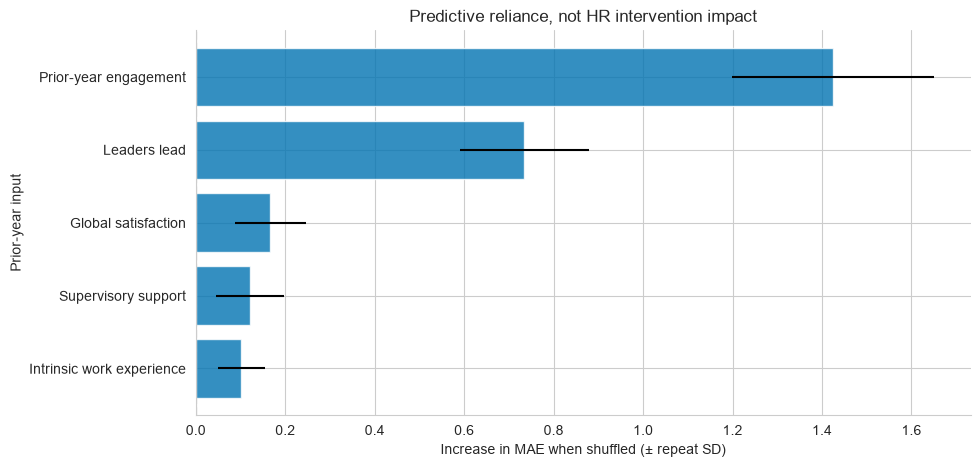

In [11]:
print("Permutation explanation model:", forecast_result["explanationModel"])
importance = pd.DataFrame(forecast_result["importance"]).sort_values("mean")
display(importance)
display(pd.Series(forecast_result["transportability"]).to_frame("group-holdout sensitivity"))
fig, ax = plt.subplots()
ax.barh(importance.label, importance["mean"], xerr=importance["std"], alpha=0.8)
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Predictive reliance, not HR intervention impact",
       xlabel="Increase in MAE when shuffled (± repeat SD)", ylabel="Prior-year input")
finish(fig, "permutation_importance")

## 10. Profile studio: describe similarities without labeling people

Latest-year complete profiles are standardized; **engagement is excluded from
clustering inputs**. KMeans candidates range from k=2 to k=5 when sample size
permits; maximum silhouette selects k. PCA provides a two-dimensional view,
not the space in which clustering is fitted.

Stability is mean adjusted Rand agreement across 30 seeded 80% subsamples
against the full solution, on common organizations. Scaling is held fixed
from the full eligible sample, so this is conditional assignment stability,
not a complete pipeline uncertainty estimate.

Profile numbers are arbitrary. They are **not diagnoses, causal segments,
employee archetypes, or labels such as “toxic” or “high risk.”**

,value
k,2
silhouette,0.434893
stability,0.885499
variance,"[0.8622308009159305, 0.07349782839070532]"


,k,score
0,2,0.434893
1,3,0.413721
2,4,0.382571
3,5,0.336392


,one-score simplification check
n,81
k,2
adjustedRand,1.0
interpretation,Compare the full-feature partition with K-mean...


,feature,pc1,pc2
0,leaders,0.494578,-0.568957
1,supervisors,0.478954,0.801721
2,intrinsic,0.509406,-0.016593
3,satisfaction,0.516238,-0.182361


Eligible latest-year organizations: 81 of 81


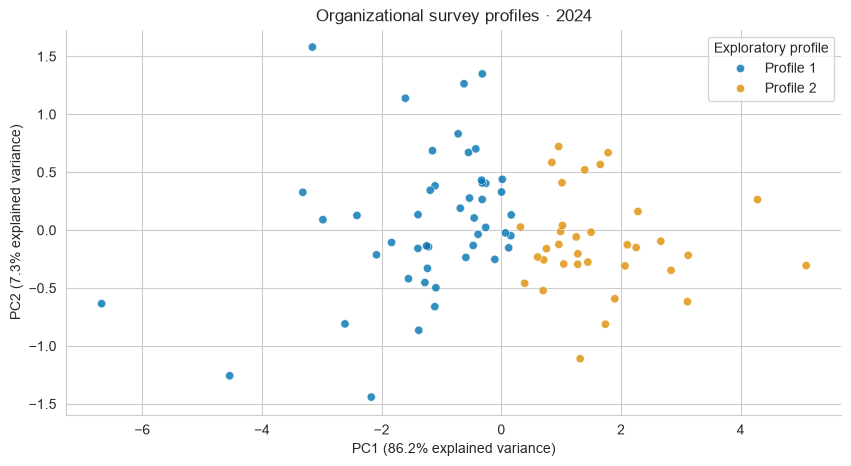

,n,engagement_context_only,leaders,supervisors,intrinsic,satisfaction
profile,,,,,,
Profile 1,47,70.094006,56.691577,80.082529,73.507912,61.897939
Profile 2,34,83.135704,76.484662,89.225508,83.696944,77.664801


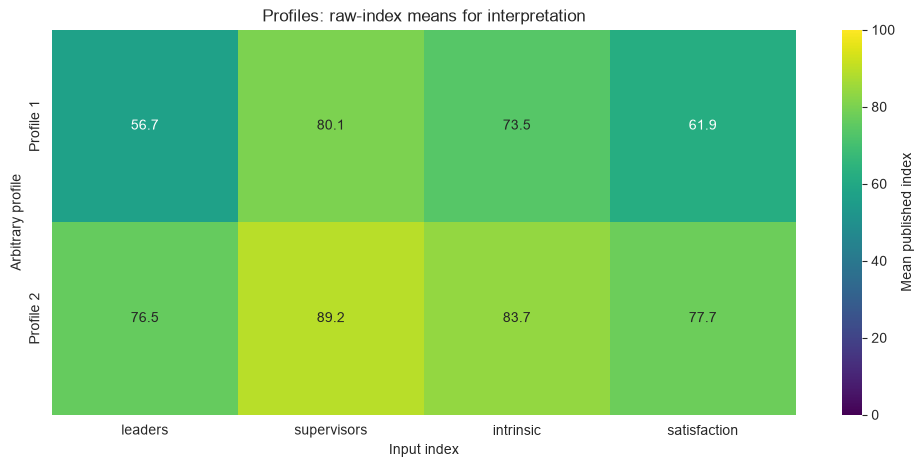

In [12]:
display(pd.Series({key: clusters[key] for key in
                   ["k", "silhouette", "stability", "variance"]}).to_frame("value"))
display(pd.DataFrame(clusters["candidateScores"]))
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

cluster_features = [row["feature"] for row in clusters["loadings"]]
eligible = latest.dropna(subset=cluster_features)
scaled = StandardScaler().fit_transform(eligible[cluster_features])
with threadpool_limits(limits=2):
    level_labels = KMeans(n_clusters=clusters["k"], n_init=30, random_state=SEED).fit_predict(
        scaled.mean(axis=1).reshape(-1, 1)
    )
full_labels = pd.DataFrame(clusters["points"]).set_index("organization").loc[
    eligible.organization, "cluster"
]
level_agreement = adjusted_rand_score(full_labels, level_labels)
if not np.isclose(level_agreement, clusters["levelCheck"]["adjustedRand"]):
    raise ValueError("One-score cluster diagnostic disagrees with persisted evidence.")
display(pd.Series(clusters["levelCheck"]).to_frame("one-score simplification check"))
loadings = pd.DataFrame(clusters["loadings"])
display(loadings)
points = pd.DataFrame(clusters["points"])
points["profile"] = points.cluster.map(lambda value: f"Profile {int(value) + 1}")
print("Eligible latest-year organizations:", len(points), "of", len(latest))
fig, ax = plt.subplots()
sns.scatterplot(points, x="x", y="y", hue="profile", alpha=0.8, ax=ax)
ax.set(title=f"Organizational survey profiles · {latest_year}",
       xlabel=f"PC1 ({clusters['variance'][0]:.1%} explained variance)",
       ylabel=f"PC2 ({clusters['variance'][1]:.1%} explained variance)")
ax.legend(title="Exploratory profile")
finish(fig, "cluster_pca")
profile_rows = [
    {"profile": item["name"], "n": item["n"],
     "engagement_context_only": item["engagement"], **item["features"]}
    for item in clusters["profiles"]
]
profile_table = pd.DataFrame(profile_rows).set_index("profile")
display(profile_table)
feature_keys = loadings.feature.tolist()
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(profile_table[feature_keys], annot=True, fmt=".1f", cmap="viridis",
            vmin=0, vmax=100, ax=ax, cbar_kws={"label": "Mean published index"})
ax.set(title="Profiles: raw-index means for interpretation", xlabel="Input index",
       ylabel="Arbitrary profile")
finish(fig, "cluster_profiles")

## 11. Retention lens: intentions are not exits

The 2024 demographic report is **unweighted**. `intent_leave` combines the
published “yes” categories for intending to leave the organization; retirement
and external departure are distinct motives. Inspect workbook headers before
giving a more specific interpretation to derived categories.

This is neither actual turnover nor employee-level attrition prediction.
The response-rate report has a different purpose and denominator. Associations
with EEI cannot be translated into an individual's departure probability,
headcount at risk, or the expected ROI of a retention intervention.

**Join limitation:** `atlas.source.INTENTION_CROSSWALK` is an explicit,
manually reviewed acronym-to-name mapping—not an official OPM harmonization
table. A mapped name must also exist in the latest index cohort. Army, Navy,
Marine Corps, USACE, and Defense 4th Estate are excluded because naming,
exclusions, or reporting scope require separate reconciliation; Air Force is
retained. No fuzzy matching or automatic component-to-parent merging is used.
Linked agencies are a selected supplement, not the entire cohort.

Linked organizations with engagement and intention to leave: 34 of 81 latest-year organizations.


n                     34.000000
rho                   -0.615267
low                   -0.846913
high                  -0.274714
leaveOneOutLow        -0.729628
leaveOneOutHigh       -0.579189
leaveOneOutValid      34.000000
bootstrapValid      3000.000000
bootstrapDraws      3000.000000
dtype: float64

,linked,label,n,medianEngagement,medianResponseRate
0,False,Not linked,47,74.206142,67.80
1,True,Linked,34,75.706125,61.05


,size,linked,unlinked
0,Large,9,0
1,Medium,16,0
2,Small,3,26
3,Very Large,6,3
4,Very Small,0,18


A distinct same-survey question, not an external or causal validation. Agency-bootstrap and leave-one-out checks are conditional on the selected linked agencies; they do not correct nonresponse, selection, or common-method bias.
Sizes with no linked agencies: ['Very Small']


,organization,intent_leave,intent_source_code,intent_response_count
557,Court Services and Offender Supervision Agency,37.2,CSOSA,295.0
559,Department of Agriculture,32.6,USDA,50695.0
560,Department of Commerce,24.4,DOC,23882.0
561,Department of Education,32.4,ED,2467.0
562,Department of Energy,27.9,DOE,11037.0
563,Department of Health and Human Services,25.5,HHS,59261.0
564,Department of Homeland Security,34.1,DHS,94177.0
565,Department of Housing and Urban Development,35.0,HUD,5546.0
566,Department of Justice,36.9,DOJ,38897.0
567,Department of Labor,32.8,DOL,8906.0


,source_abbreviation,mapped_organization
0,USDA,Department of Agriculture
1,DHS,Department of Homeland Security
2,DOJ,Department of Justice
3,HHS,Department of Health and Human Services
4,USDT,Department of the Treasury
5,DOC,Department of Commerce
6,DOE,Department of Energy
7,DOI,Department of the Interior
8,DOL,Department of Labor
9,DOT,Department of Transportation


,count,mean,std,min,25%,50%,75%,max
intent_leave,34.0,29.858824,5.911884,14.0,25.900,31.45,32.750,44.7
intent_retire,34.0,5.891176,1.506424,2.3,5.225,5.65,6.375,9.5
intent_external,34.0,3.929412,1.878995,0.8,2.825,3.75,5.100,8.0
response_rate,81.0,62.614815,17.420032,18.4,53.400,65.80,75.400,95.7
response_count,81.0,8323.234568,18186.836241,12.0,70.000,430.00,2467.000,94177.0
surveyed,81.0,20318.432099,48073.020316,13.0,110.000,682.00,4385.000,211371.0


,measure,n_organizations,rho,p_exploratory,q_BH_auxiliary_family
0,intent_leave,34,-0.615267,0.000108,0.000431
1,intent_retire,34,-0.424257,0.012396,0.016527
2,intent_external,34,-0.144343,0.415387,0.415387
3,response_rate,81,0.377845,0.000506,0.001012


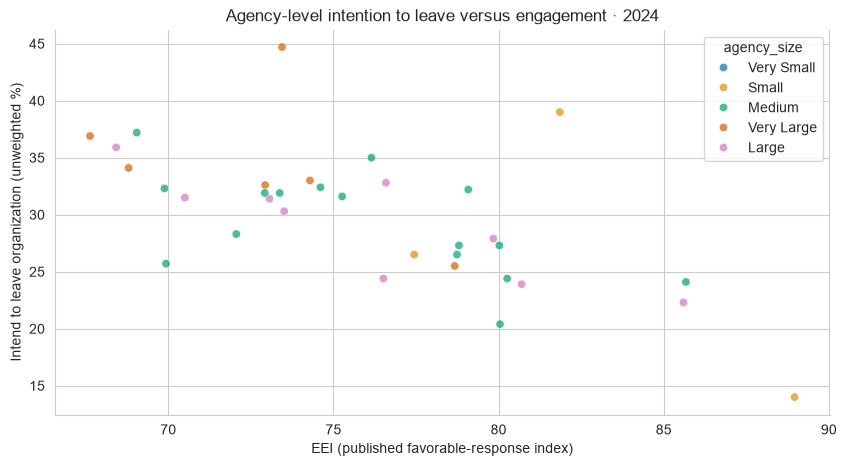

In [13]:
retention_cols = [c for c in ["intent_leave", "intent_retire", "intent_external",
                              "response_rate", "response_count", "surveyed"] if c in latest]
intention_pairs = latest.dropna(subset=["engagement", "intent_leave"])
print("Linked organizations with engagement and intention to leave:",
      len(intention_pairs), "of", len(latest), "latest-year organizations.")
if len(intention_pairs) != evidence["intentionAnalysis"]["n"]:
    raise ValueError("Intention sample differs between CSV and JSON; regenerate the pipeline.")
intention_check = intention_analysis(latest)
for key in ["rho", "low", "high", "leaveOneOutLow", "leaveOneOutHigh"]:
    if not np.isclose(intention_check[key], evidence["intentionAnalysis"][key]):
        raise ValueError(f"Intention sensitivity diagnostic mismatch: {key}")
display(pd.Series({k: intention_check[k] for k in
                   ["n", "rho", "low", "high", "leaveOneOutLow", "leaveOneOutHigh",
                    "leaveOneOutValid", "bootstrapValid", "bootstrapDraws"]}))
display(pd.DataFrame(intention_check["selection"]))
display(pd.DataFrame(intention_check["sizeComposition"]))
print(intention_check["interpretation"])
print("Sizes with no linked agencies:", intention_check["unrepresentedSizes"])
provenance_cols = ["organization", "intent_leave"] + [
    c for c in ["intent_source_code", "intent_response_count"] if c in latest
]
display(intention_pairs[provenance_cols].sort_values("organization"))
display(pd.DataFrame([{"source_abbreviation": code, "mapped_organization": name}
                      for code, name in INTENTION_CROSSWALK.items()]))
display(latest[retention_cols].describe().T)
retention_rows = []
for col in [c for c in retention_cols if c not in ["surveyed", "response_count"]]:
    pair = latest[["engagement", col]].dropna()
    if len(pair) >= 5 and pair.nunique().min() > 1:
        rho, p = stats.spearmanr(pair.engagement, pair[col])
        retention_rows.append({"measure": col, "n_organizations": len(pair),
                               "rho": rho, "p_exploratory": p})
retention_tests = pd.DataFrame(retention_rows)
if not retention_tests.empty:
    retention_tests["q_BH_auxiliary_family"] = benjamini_hochberg(retention_tests.p_exploratory)
    display(retention_tests)
if "intent_leave" in latest and latest.intent_leave.notna().sum() >= 3:
    fig, ax = plt.subplots()
    sns.scatterplot(latest, x="engagement", y="intent_leave", hue="agency_size",
                    alpha=0.7, ax=ax)
    ax.set(title=f"Agency-level intention to leave versus engagement · {latest_year}",
           xlabel="EEI (published favorable-response index)",
           ylabel="Intend to leave organization (unweighted %)")
    finish(fig, "intention_lens")

## 12. HR decision briefing: evidence → question → safe next step

| Evidence type | Appropriate use | Inappropriate use |
|---|---|---|
| Distribution / trend | Identify variation and comparability questions | National employee trend from equal-agency means |
| Concurrent index association | Describe co-occurring perceptions | Call a shared component an independent driver |
| Annual-change association | Prioritize hypotheses for triangulation | Claim that an intervention causes the coefficient |
| Locked forecast | Benchmark next-year organization-level expectations | Predict individual performance or departures |
| Calibrated interval | Communicate uncertainty and observed coverage | Promise nominal coverage under arbitrary shifts |
| Profile cluster | Structure exploratory leadership conversations | Diagnose organizations or classify employees |
| Intention aggregate | Discuss reasons people consider leaving | Estimate realized turnover or monetary ROI |

**A practical action sequence**
1. Verify source coverage and year comparability with the public technical reports.
2. Bring domain experts into interpretation; compare index overlap with item wording.
3. Use interviews or approved local research to triangulate a specific hypothesis.
4. Design a prospective evaluation with a comparison group before claiming impact.
5. Monitor forecast errors, interval coverage, response patterns, and composition
   at the next release; freeze a new evaluation plan before opening its outcomes.

No respondent-level psychometric reliability, measurement invariance,
protected-group fairness, or individual-level causal inference can be estimated
from this panel. Organization-size error checks do not substitute for those tests.

In [14]:
winner = metrics.loc[metrics.name.eq(forecast_result["selected"])].iloc[0]
baseline = metrics.loc[metrics.name.eq("Persistence")].iloc[0]
display(Markdown(
    f"### Evidence-led summary\n"
    f"- Panel: **{len(df):,} organization-years**, **{df.organization.nunique():,} "
    f"exact-name organizations**, {int(df.year.min())}–{latest_year}.\n"
    f"- Balanced all-year cohort: **{len(balanced):,} organizations**; compare its trajectory "
    f"with all-observed means before attributing change.\n"
    f"- Development-selected forecast: **{forecast_result['selected']}**. "
    f"Final-test MAE **{winner.mae:.2f} EEI points** "
    f"(agency-bootstrap 95% CI {winner.low:.2f}–{winner.high:.2f}); "
    f"persistence MAE **{baseline.mae:.2f}**. This is not a causal or individual model.\n"
    f"- Final-test interval coverage: **{forecast_result['interval']['coverage']:.1%}**, "
    f"versus nominal **{forecast_result['interval']['nominal']:.0%}**; "
    f"mean width **{forecast_result['interval']['width']:.2f} points**.\n"
    f"- Exploratory profiles: **{clusters['k']}**, silhouette "
    f"**{clusters['silhouette']:.3f}**, conditional mean subsample ARI "
    f"**{clusters['stability']:.3f}**. Do not turn them into diagnostic labels.\n"
    f"- Intention-to-leave supplement: **{len(intention_pairs):,} linked organizations** "
    f"using a manually reviewed, non-official abbreviation crosswalk; "
    f"intentions are not actual turnover.\n"
    f"- Outstanding limitations: overlapping index content, response selection, "
    f"agency dependence, publication rounding, temporal comparability, and "
    f"unobserved respondent composition."
))
print("Notebook figures saved to:", FIGURES.relative_to(ROOT).as_posix())

### Evidence-led summary
- Panel: **630 organization-years**, **85 exact-name organizations**, 2017–2024.
- Balanced all-year cohort: **72 organizations**; compare its trajectory with all-observed means before attributing change.
- Development-selected forecast: **Persistence**. Final-test MAE **3.34 EEI points** (agency-bootstrap 95% CI 2.17–4.91); persistence MAE **3.34**. This is not a causal or individual model.
- Final-test interval coverage: **86.4%**, versus nominal **90%**; mean width **12.48 points**.
- Exploratory profiles: **2**, silhouette **0.435**, conditional mean subsample ARI **0.885**. Do not turn them into diagnostic labels.
- Intention-to-leave supplement: **34 linked organizations** using a manually reviewed, non-official abbreviation crosswalk; intentions are not actual turnover.
- Outstanding limitations: overlapping index content, response selection, agency dependence, publication rounding, temporal comparability, and unobserved respondent composition.

Notebook figures saved to: outputs/figures


## Appendix: the complete persisted evidence

Tables and plots above are rendered from processed files; the full JSON below
preserves upstream findings and source metadata, including sections not
summarized in the narrative. There are no hardcoded empirical findings.

In [15]:
print(json.dumps(evidence, indent=2, ensure_ascii=False))

{
  "meta": {
    "title": "The Engagement Atlas",
    "source": "US OPM Federal Employee Viewpoint Survey",
    "sourceUrl": "https://www.opm.gov/fevs/reports/data-reports/",
    "licenseUrl": "https://www.law.cornell.edu/uscode/text/17/105",
    "years": [
      2017,
      2018,
      2019,
      2020,
      2021,
      2022,
      2023,
      2024
    ],
    "latestYear": 2024,
    "orgCount": 85,
    "rowCount": 630,
    "latestOrgCount": 81,
    "features": [
      {
        "key": "leaders",
        "label": "Leaders lead"
      },
      {
        "key": "supervisors",
        "label": "Supervisory support"
      },
      {
        "key": "intrinsic",
        "label": "Intrinsic work experience"
      },
      {
        "key": "satisfaction",
        "label": "Global satisfaction"
      }
    ],
    "units": "Published percentage index, 0–100",
    "repositoryUrl": "https://github.com/mberca/engagement-atlas",
    "profileUrl": "https://github.com/mberca"
  },
  "annual": [
    